# 04 - Visual Retrieval (ColQwen2) and Fusion

Path B: searching whole page images directly, with no parsing, OCR or summaries.
Then fusing it with Path A (hybrid text search) and measuring retrieval and answer accuracy.

**Runtime: T4 GPU is required** (Runtime -> Change runtime type -> T4 GPU).

## Setup

In [1]:
# Installing libraries (removing Colab's old torchao, which clashes with peft)
!pip uninstall -y -q torchao
!pip install -q colpali-engine pymupdf chromadb sentence-transformers google-genai rank_bm25

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.4/112.4 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 35.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 35.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 44.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.3/206.3 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 775.8/775.8 kB 26.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7

In [2]:
# Mounting Drive, checking the GPU and loading saved files
from google.colab import drive
drive.mount('/content/drive')

import json, re, time, random, shutil
from pathlib import Path
import numpy as np, pandas as pd
import torch, chromadb, fitz
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

assert torch.cuda.is_available(), "No GPU: switch to Runtime -> Change runtime type -> T4 GPU"
device = "cuda"
print(torch.cuda.get_device_name(0))

PROJECT_DIR = Path("/content/drive/MyDrive/annual-report-rag")
EVAL_DIR = PROJECT_DIR / "eval"
PAGE_EMB_DIR = PROJECT_DIR / "page_embeddings"
PAGE_EMB_DIR.mkdir(exist_ok=True)

docstore = json.loads((PROJECT_DIR / "docstore.json").read_text())
meta = pd.read_csv(PROJECT_DIR / "metadata.csv")
meta["year"] = meta["year"].astype(str)

# loading the golden set from Notebook 3
golden = pd.read_csv(EVAL_DIR / "golden.csv")
golden["gold_pages"] = golden.gold_pages.map(
    lambda s: [int(x) for x in str(s).split(";") if x and x != "nan"])
golden["gold_doc_id"] = golden.gold_doc_id.fillna("")
answerable = golden[golden.qtype != "unanswerable"]
print(f"{len(golden)} questions ({len(answerable)} answerable)")
display(meta[["doc_id", "company", "year", "pages", "path"]])

Mounted at /content/drive
Tesla T4
56 questions (51 answerable)


,doc_id,company,year,pages,path
0,au_small_finance_bank_2023,au_small_finance_bank,2023,331,/content/drive/MyDrive/annual-report-rag/repor...
1,au_small_finance_bank_2024,au_small_finance_bank,2024,179,/content/drive/MyDrive/annual-report-rag/repor...
2,au_small_finance_bank_2025,au_small_finance_bank,2025,182,/content/drive/MyDrive/annual-report-rag/repor...


## Path A: hybrid text search

In [3]:
# Rebuilding Path A: Chroma dense search + BM25 + RRF, with company/year filters
from sentence_transformers import SentenceTransformer
from rank_bm25 import BM25Okapi

CHROMA_LOCAL = f"/content/chroma_{int(time.time())}"
shutil.copytree(PROJECT_DIR / "chroma", CHROMA_LOCAL)
col = chromadb.PersistentClient(path=CHROMA_LOCAL).get_collection("annual_reports")
embedder = SentenceTransformer("BAAI/bge-small-en-v1.5", device=device)

QUERY_PREFIX = "Represent this sentence for searching relevant passages: "
COMPANIES = sorted({d["company"] for d in docstore.values()})
YEARS = sorted({d["year"] for d in docstore.values()})
ALIASES = {c: [c.replace("_", " ")] for c in COMPANIES}
ALIASES.setdefault("au_small_finance_bank", []).extend(["au bank", "au sfb"])

def find_years(q):
    ys, q = set(), q.lower()
    for m in re.finditer(r"(20\d{2})\s*[-–/]\s*(\d{2,4})", q):
        end = m.group(2); ys.add(end if len(end) == 4 else "20" + end)
    q = re.sub(r"(20\d{2})\s*[-–/]\s*(\d{2,4})", " ", q)
    for m in re.finditer(r"fy\s*'?(\d{2,4})\b", q):
        y = m.group(1); ys.add(y if len(y) == 4 else "20" + y)
    q = re.sub(r"fy\s*'?(\d{2,4})\b", " ", q)
    ys.update(re.findall(r"\b(20\d{2})\b", q))
    return sorted(y for y in ys if y in YEARS)

def parse_query(q):
    ql = q.lower()
    company = next((c for c, names in ALIASES.items() if any(n in ql for n in names)), None)
    return company, find_years(q)

def make_where(company, years):
    conds = []
    if company: conds.append({"company": company})
    if years:   conds.append({"year": years[0]} if len(years) == 1 else {"year": {"$in": years}})
    return None if not conds else conds[0] if len(conds) == 1 else {"$and": conds}

def dense_search(q, n=30, company=None, years=None):
    qv = embedder.encode([QUERY_PREFIX + q], normalize_embeddings=True)[0].tolist()
    return col.query(query_embeddings=[qv], n_results=n, where=make_where(company, years))["ids"][0]

_all = col.get(include=["documents"])
doc_text = dict(zip(_all["ids"], _all["documents"]))
TOKEN = re.compile(r"[a-z0-9]+(?:[.,][0-9]+)*")
def tok(s): return TOKEN.findall(s.lower())
bm_ids = _all["ids"]
bm25 = BM25Okapi([tok(doc_text[i]) for i in bm_ids])

def bm25_search(q, n=30, company=None, years=None):
    out = []
    for j in np.argsort(-bm25.get_scores(tok(q))):
        d = docstore[bm_ids[j]]
        if company and d["company"] != company: continue
        if years and d["year"] not in years: continue
        out.append(bm_ids[j])
        if len(out) >= n: break
    return out

def rrf(*ranked_lists, k=60, top=30):
    s = {}
    for L in ranked_lists:
        for r, i in enumerate(L, 1):
            s[i] = s.get(i, 0) + 1 / (k + r)
    return [i for i, _ in sorted(s.items(), key=lambda x: -x[1])][:top]

def r_hybrid(q, top=10):
    c, y = parse_query(q)
    return rrf(dense_search(q, 30, c, y), bm25_search(q, 30, c, y))[:top]

print("Path A ready:", [docstore[i]["page"] for i in r_hybrid("gross NPA closing balance FY 2023-24")[:5]])

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Path A ready: [148, 149, 148, 54, 152]


## Path B: embedding every page image with ColQwen2

In [4]:
# Loading ColQwen2 (a ColPali-style model built on Qwen2-VL-2B)
from colpali_engine.models import ColQwen2, ColQwen2Processor

COLQWEN = "vidore/colqwen2-v1.0"
vmodel = ColQwen2.from_pretrained(COLQWEN, torch_dtype=torch.float16, device_map=device).eval()
vproc = ColQwen2Processor.from_pretrained(COLQWEN)
print(f"GPU memory used: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

adapter_config.json:   0%|          | 0.00/728 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.16k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/56.5k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/392 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/613 [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

GPU memory used: 4.6 GB


au_small_finance_bank_2023 (794, 1040)


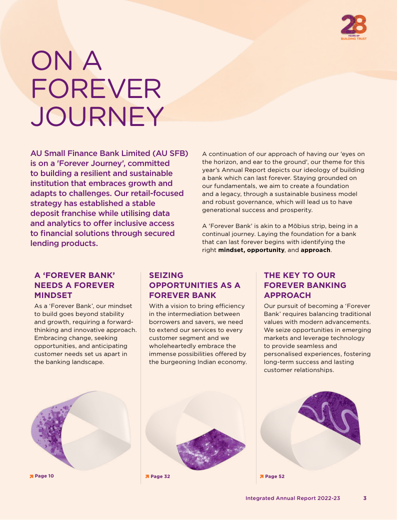

In [5]:
# Rendering a page of a report as an image
def render_page(path, page_no, dpi=96):
    with fitz.open(path) as d:
        pix = d[page_no - 1].get_pixmap(dpi=dpi)           # page numbers start at 1
        return Image.frombytes("RGB", (pix.width, pix.height), pix.samples)

# testing one page
row = meta.iloc[0]
img = render_page(row.path, 5)
print(row.doc_id, img.size)
display(img.resize((img.width // 2, img.height // 2)))

In [6]:
# Embedding every page, saved to Drive in 40-page chunks so a crash only loses one chunk
CHUNK, BATCH = 40, 4

def embed_images(imgs):
    batch = vproc.process_images(imgs).to(device)
    with torch.no_grad():
        out = vmodel(**batch)                               # (batch, tokens, 128)
    mask = batch["attention_mask"].bool()
    return [out[j][mask[j]].to(torch.float16).cpu() for j in range(len(imgs))]  # dropping padding

t0 = time.time()
for m in meta.itertuples():
    for start in range(1, m.pages + 1, CHUNK):
        f = PAGE_EMB_DIR / f"{m.doc_id}_{start:04d}.pt"
        if f.exists():
            continue
        pages = list(range(start, min(start + CHUNK, m.pages + 1)))
        embs = []
        for b in range(0, len(pages), BATCH):
            imgs = [render_page(m.path, p) for p in pages[b:b + BATCH]]
            embs += embed_images(imgs)
        torch.save({"doc_id": m.doc_id, "pages": pages, "embs": embs}, f)
        print(f"   {m.doc_id} pages {pages[0]}-{pages[-1]} done | {(time.time() - t0) / 60:.1f} min")
    print(f"✅ {m.doc_id}")

✅ au_small_finance_bank_2023
✅ au_small_finance_bank_2024
✅ au_small_finance_bank_2025


In [7]:
# Loading all page embeddings into one index
page_keys, page_embs, page_meta = [], [], []
doc_info = meta.set_index("doc_id")
for f in sorted(PAGE_EMB_DIR.glob("*.pt")):
    chunk = torch.load(f)
    for p, e in zip(chunk["pages"], chunk["embs"]):
        page_keys.append(f"{chunk['doc_id']}|{p}")
        page_embs.append(e)
        page_meta.append({"doc_id": chunk["doc_id"], "page": p,
                          "company": doc_info.loc[chunk["doc_id"], "company"],
                          "year": str(doc_info.loc[chunk["doc_id"], "year"])})
print(f"{len(page_keys)} pages indexed, ~{sum(e.numel() for e in page_embs) * 2 / 1e6:.0f} MB")

692 pages indexed, ~134 MB


['au_small_finance_bank_2023|82', 'au_small_finance_bank_2023|96', 'au_small_finance_bank_2023|33']


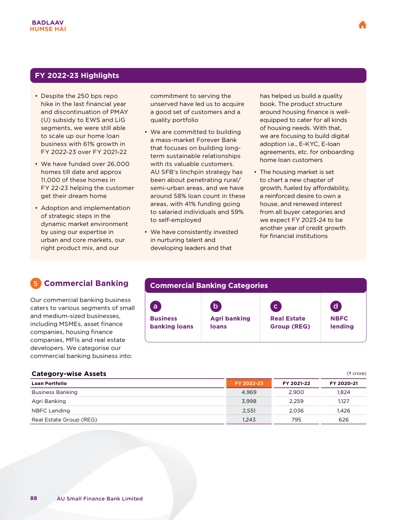

In [8]:
# Searching page images: late interaction (each query token finds its best-matching image patch)
def visual_search(q, n=10, company=None, years=None):
    idx = [i for i, m in enumerate(page_meta)
           if (not company or m["company"] == company) and (not years or m["year"] in years)]
    batch = vproc.process_queries([q]).to(device)
    with torch.no_grad():
        qe = vmodel(**batch)[0].to(torch.float16)
    scores = vproc.score_multi_vector([qe], [page_embs[i] for i in idx], device=device)[0]
    order = torch.argsort(scores, descending=True)[:n].tolist()
    return [page_keys[idx[j]] for j in order]

def r_visual(q, top=10):
    c, y = parse_query(q)
    return visual_search(q, top, c, y)

q = "Show me the business segments of AU Small Finance Bank in FY2023"
hits = r_visual(q, 3)
print(hits)
doc, p = hits[0].split("|")
img = render_page(doc_info.loc[doc, "path"], int(p))
display(img.resize((img.width // 2, img.height // 2)))

## Comparing Path A, Path B and the fusion (page level)

In [9]:
# Turning item rankings into page rankings, and fusing both paths
def page_key(item_id):
    d = docstore[item_id]
    return f"{d['doc_id']}|{d['page']}"

def to_pages(item_ids):
    seen, out = set(), []
    for i in item_ids:
        k = page_key(i)
        if k not in seen:
            seen.add(k); out.append(k)
    return out

def p_text(q):   return to_pages(r_hybrid(q, 30))[:10]
def p_visual(q): return r_visual(q, 10)
def p_fused(q):  return rrf(to_pages(r_hybrid(q, 30)), r_visual(q, 30), top=10)

PAGE_VARIANTS = {"A. text hybrid": p_text, "B. visual pages": p_visual, "A+B fused": p_fused}
COLS = ["hit@1", "hit@3", "hit@5", "hit@10", "mrr"]

def gold_page(key, row):
    doc, p = key.split("|")
    return doc == row.gold_doc_id and int(p) in row.gold_pages

def score(keys, ok):
    first = next((r for r, k in enumerate(keys[:10], 1) if ok(k)), None)
    out = {f"hit@{k}": int(first is not None and first <= k) for k in (1, 3, 5, 10)}
    out["mrr"] = 1 / first if first else 0.0
    return out

page_results = {name: {row.qid: f(row.question) for row in tqdm(list(answerable.itertuples()), desc=name)}
                for name, f in PAGE_VARIANTS.items()}

strict = pd.DataFrame([{"variant": v, "qid": row.qid, "qtype": row.qtype,
                        **score(page_results[v][row.qid], lambda k, row=row: gold_page(k, row))}
                       for v in PAGE_VARIANTS for row in answerable.itertuples()])
print("    Strict (gold page)    ")
display(strict.groupby("variant")[COLS].mean().round(3).loc[list(PAGE_VARIANTS)])
display(strict.pivot_table(index="variant", columns="qtype", values="hit@5").round(2).loc[list(PAGE_VARIANTS)])

A. text hybrid:   0%|          | 0/51 [00:00<?, ?it/s]

B. visual pages:   0%|          | 0/51 [00:00<?, ?it/s]

A+B fused:   0%|          | 0/51 [00:00<?, ?it/s]

    Strict (gold page)    


,hit@1,hit@3,hit@5,hit@10,mrr
variant,,,,,
A. text hybrid,0.588,0.706,0.824,0.902,0.670
B. visual pages,0.373,0.529,0.588,0.725,0.482
A+B fused,0.490,0.706,0.804,0.941,0.622


qtype,hand,image,table,text
variant,,,,
A. text hybrid,0.75,0.7,0.95,0.75
B. visual pages,0.00,0.7,0.67,0.56
A+B fused,0.50,0.9,0.76,0.88


In [10]:
# Judging pages that were never judged before, using Gemini on the page image (cached)
from google import genai
from google.genai import types
from google.colab import userdata

client = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))
JUDGE_MODEL = "gemini-3.5-flash-lite"

def gemini_json(contents, model=JUDGE_MODEL, retries=5):
    for a in range(retries):
        try:
            r = client.models.generate_content(model=model, contents=contents,
                config=types.GenerateContentConfig(temperature=0, response_mime_type="application/json"))
            return json.loads(r.text)
        except json.JSONDecodeError:
            time.sleep(3)
        except Exception as ex:
            m = str(ex)
            if "503" in m or "UNAVAILABLE" in m: time.sleep(5 * 2 ** a)
            elif "429" in m or "RESOURCE_EXHAUSTED" in m:
                if "PerDay" in m: raise RuntimeError(f"Daily quota reached for {model}, rerun tomorrow")
                time.sleep(30)
            else: raise
    return None

# item-level judgments from Notebook 3: a page counts if any judged-relevant item sits on it
rel = json.loads((EVAL_DIR / "relevance_cache.json").read_text())
items_on_page = {}
for i, d in docstore.items():
    items_on_page.setdefault(f"{d['doc_id']}|{d['page']}", []).append(i)

PAGE_REL_CACHE = EVAL_DIR / "page_relevance_cache.json"
page_rel = json.loads(PAGE_REL_CACHE.read_text()) if PAGE_REL_CACHE.exists() else {}

def known(qid, key):
    row = rows_by_qid[qid]
    if gold_page(key, row): return True
    if any(rel.get(f"{qid}|{i}") for i in items_on_page.get(key, [])): return True
    return page_rel.get(f"{qid}|{key}")                       # None if never judged

REL_PROMPT = """You check search results for a question about a bank's annual report.
QUESTION: {q}
REFERENCE ANSWER: {a}
Each image below is a full report page. For EACH page, decide: does it contain the information
needed to answer the question correctly (consistent with the reference answer, right fiscal year)?
Merely mentioning the topic is NOT enough.
Return ONLY a JSON list: [{{"pid": "P1", "relevant": true}}, ...]"""

rows_by_qid = {r.qid: r for r in answerable.itertuples()}
for row in tqdm(list(answerable.itertuples())):
    keys = {k for v in PAGE_VARIANTS for k in page_results[v][row.qid][:5]}
    todo = sorted(k for k in keys if known(row.qid, k) is None)
    if not todo:
        continue
    pid = {f"P{j + 1}": k for j, k in enumerate(todo)}
    contents = [REL_PROMPT.format(q=row.question, a=row.answer)]
    for p, k in pid.items():
        doc, pg = k.split("|")
        contents += [f"{p}: [{doc}, p.{pg}]", render_page(doc_info.loc[doc, "path"], int(pg), dpi=110)]
    out = gemini_json(contents)
    if isinstance(out, dict): out = out.get("items", [out])
    for r in out or []:
        if isinstance(r, dict) and r.get("pid") in pid:
            page_rel[f"{row.qid}|{pid[r['pid']]}"] = bool(r.get("relevant"))
    PAGE_REL_CACHE.write_text(json.dumps(page_rel))
    time.sleep(4)
print(f"{len(page_rel)} page judgments cached")

  0%|          | 0/51 [00:00<?, ?it/s]

407 page judgments cached


In [11]:
# Scoring all three variants with judged relevance
judged = pd.DataFrame([{"variant": v, "qid": row.qid, "qtype": row.qtype,
                        **score(page_results[v][row.qid][:5], lambda k, q=row.qid: bool(known(q, k)))}
                       for v in PAGE_VARIANTS for row in answerable.itertuples()])
judged = judged.drop(columns=["hit@10"]).rename(columns=lambda c: "j_" + c if c.startswith(("hit", "mrr")) else c)

print("    Judged (page level)    ")
display(judged.groupby("variant")[["j_hit@1", "j_hit@3", "j_hit@5", "j_mrr"]].mean().round(3).loc[list(PAGE_VARIANTS)])
display(judged.pivot_table(index="variant", columns="qtype", values="j_hit@5").round(2).loc[list(PAGE_VARIANTS)])

strict.to_csv(EVAL_DIR / "page_retrieval_strict.csv", index=False)
judged.to_csv(EVAL_DIR / "page_retrieval_judged.csv", index=False)

    Judged (page level)    


,j_hit@1,j_hit@3,j_hit@5,j_mrr
variant,,,,
A. text hybrid,0.765,0.922,0.941,0.842
B. visual pages,0.588,0.706,0.765,0.651
A+B fused,0.667,0.863,0.922,0.772


qtype,hand,image,table,text
variant,,,,
A. text hybrid,0.75,1.0,0.95,0.94
B. visual pages,0.75,0.9,0.76,0.69
A+B fused,1.00,1.0,0.86,0.94


3 questions answered only by the visual path

[table] What was the adjusted profit after tax for AU Small Finance Bank for the year ended March 31, 2024 in FY 2023-24?
  found: au_small_finance_bank_2024|69


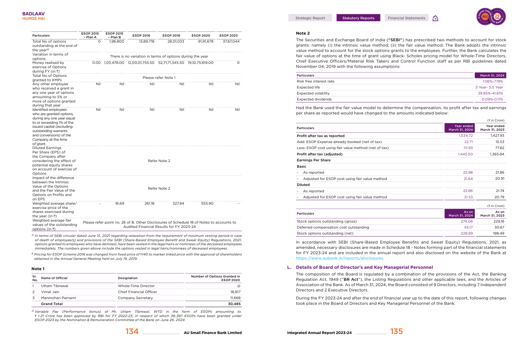


[text] What was the age of Mr. Harun Rasid Khan, Independent Director, during FY 2022-23?
  found: au_small_finance_bank_2023|128


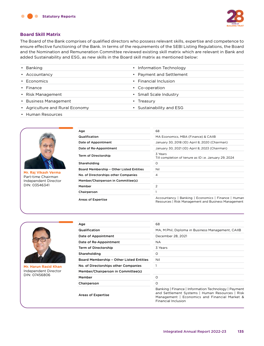


[hand] How did total advances change between FY23 and FY24?
  found: au_small_finance_bank_2024|38


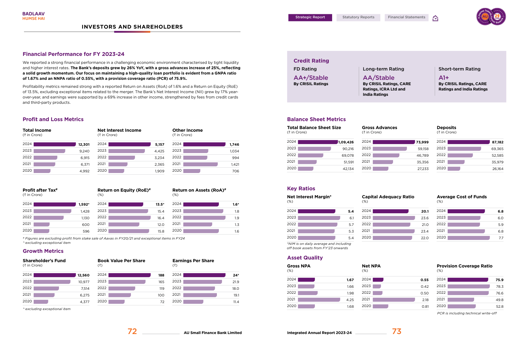

In [12]:
# Finding questions only the visual path got right (the case for Path B)
only_b = [row for row in answerable.itertuples()
          if not any(known(row.qid, k) for k in page_results["A. text hybrid"][row.qid][:5])
          and any(known(row.qid, k) for k in page_results["B. visual pages"][row.qid][:5])]
print(f"{len(only_b)} questions answered only by the visual path")
for row in only_b[:3]:
    k = next(k for k in page_results["B. visual pages"][row.qid][:5] if known(row.qid, k))
    print(f"\n[{row.qtype}] {row.question}\n  found: {k}")
    doc, p = k.split("|")
    img = render_page(doc_info.loc[doc, "path"], int(p))
    display(img.resize((img.width // 3, img.height // 3)))

## Answer accuracy with both paths

In [13]:
# Answering with Path A items plus up to 2 extra page images from Path B (cached)
ANS_MODEL = "gemini-3.5-flash-lite"          # same model as Notebook 3, so results are comparable
FUSED = "8. hybrid + visual pages"

ANSWER_PROMPT = """You are a financial analyst assistant answering questions about company annual reports.
Rules:
- Use ONLY the sources provided below. Never use outside knowledge.
- Only report numbers that appear in the sources. You MAY compute a simple difference or
  % change between two figures stated in the sources, and must show the calculation.
  NEVER derive new quantities (e.g. back-calculating a total from a percentage).
- Quote exact numbers with their units (₹ crore, %, etc.) and fiscal year.
- Cite every fact like [AU Small Finance Bank FY2024, p.148].
- Include only points that directly answer the question; leave out tangential data.
- If the sources don't contain the answer, reply: "I couldn't find this in the provided reports."
- Keep it concise: a direct answer first, then 1-3 supporting points."""

def cite(company, year, page):
    return f"[{company.replace('_', ' ').title()} FY{year}, p.{page}]"

def fused_sources(q):
    c, y = parse_query(q)
    items = r_hybrid(q)[:6]
    covered = {page_key(i) for i in items}
    pages = [k for k in visual_search(q, 10, c, y) if k not in covered][:2]
    return items, pages

def build_contents(q, items, pages):
    contents = [ANSWER_PROMPT, f"QUESTION: {q}", "SOURCES:"]
    k = 0
    for i in items:
        k += 1; h = docstore[i]; src = cite(h["company"], h["year"], h["page"])
        if h["type"] == "image":
            contents += [f"Source {k} {src}: chart. Summary: {h.get('summary', '')}", Image.open(h["image_path"])]
        elif h["type"] == "table":
            contents.append(f"Source {k} {src}: table\n{h['content'][:6000]}")
        else:
            contents.append(f"Source {k} {src}: text\n{h['content']}")
    for key in pages:
        k += 1; doc, p = key.split("|"); m = doc_info.loc[doc]
        contents += [f"Source {k} {cite(m.company, m.year, p)}: full page image",
                     render_page(m.path, int(p), dpi=130)]
    return contents

def gemini_text(contents, model=ANS_MODEL, retries=5):
    for a in range(retries):
        try:
            return client.models.generate_content(model=model, contents=contents,
                config=types.GenerateContentConfig(temperature=0)).text
        except Exception as ex:
            m = str(ex)
            if "503" in m or "UNAVAILABLE" in m: time.sleep(5 * 2 ** a)
            elif "429" in m or "RESOURCE_EXHAUSTED" in m:
                if "PerDay" in m: raise RuntimeError(f"Daily quota reached for {model}, rerun tomorrow")
                time.sleep(30)
            else: raise
    return None

ANS_CACHE = EVAL_DIR / "answers_cache.json"
answers = json.loads(ANS_CACHE.read_text()) if ANS_CACHE.exists() else {}
for row in tqdm(list(golden.itertuples())):
    key = f"{FUSED}|{row.qid}"
    if key in answers:
        continue
    text = gemini_text(build_contents(row.question, *fused_sources(row.question)))
    if text:
        answers[key] = text
        ANS_CACHE.write_text(json.dumps(answers, ensure_ascii=False))
    time.sleep(4)
print(f"{sum(k.startswith(FUSED) for k in answers)} fused answers cached")

  0%|          | 0/56 [00:00<?, ?it/s]

56 fused answers cached


In [14]:
# Grading the new answers (short IDs so replies always match)
GRADE_PROMPT = """You grade answers from a financial Q&A system against reference answers.
For EACH item, compare SYSTEM ANSWER to REFERENCE ANSWER and give a verdict:
- "correct": the key facts and numbers match the reference (minor wording or rounding is fine)
- "partial": some key facts right, but some missing or wrong
- "incorrect": key facts wrong, OR it gave an answer when the reference is "NOT FOUND"
- "refused": the system said it couldn't find the answer
Return ONLY a JSON list: [{"id": "A1", "verdict": "correct"}, ...]"""

GRADE_CACHE = EVAL_DIR / "grades_cache.json"
grades = json.loads(GRADE_CACHE.read_text()) if GRADE_CACHE.exists() else {}
qa = golden.set_index("qid")

todo = [k for k in answers if k.startswith(FUSED) and k not in grades]
print(f"{len(todo)} answers to grade")
for b in tqdm(range(0, len(todo), 5)):
    ids = {f"A{j + 1}": k for j, k in enumerate(todo[b:b + 5])}
    items = [f"ID: {a}\nQUESTION: {qa.loc[k.split('|')[1], 'question']}\n"
             f"REFERENCE ANSWER: {qa.loc[k.split('|')[1], 'answer']}\nSYSTEM ANSWER: {answers[k]}"
             for a, k in ids.items()]
    out = gemini_json([GRADE_PROMPT] + items)
    if isinstance(out, dict): out = out.get("items", [out])
    if not out:
        print(f"   no reply for batch {b // 5}, rerun this cell later"); continue
    for r in out:
        if isinstance(r, dict) and r.get("id") in ids:
            grades[ids[r["id"]]] = str(r.get("verdict", "")).strip().lower()
    GRADE_CACHE.write_text(json.dumps(grades))
    time.sleep(4)
print(f"{len(grades)} grades cached")

0 answers to grade


0it [00:00, ?it/s]

168 grades cached


In [15]:
# Building the final comparison (refusals detected from the answer text itself)
def refused(text):
    return "couldn't find this in the provided reports" in (text or "").lower().replace("’", "'")

VARIANTS_TO_COMPARE = ["2. dense + filters", "4. hybrid (RRF)", FUSED]
g = pd.DataFrame([{"variant": k.split("|")[0], "qid": k.split("|")[1], "verdict": v,
                   "refused": refused(answers.get(k))}
                  for k, v in grades.items() if k.split("|")[0] in VARIANTS_TO_COMPARE])
g["answerable"] = g.qid.map(qa["qtype"]) != "unanswerable"
g["qtype"] = g.qid.map(qa["qtype"])

def summarize(df):
    a, u = df[df.answerable], df[~df.answerable]
    return pd.Series({
        "correct": round((a.verdict == "correct").mean(), 3),
        "correct+partial": round(a.verdict.isin(["correct", "partial"]).mean(), 3),
        "wrongly refused": round(a.refused.mean(), 3),
        "unanswerable refused": f"{u.refused.sum()}/{len(u)}",
    })

final = g.groupby("variant")[["answerable", "verdict", "refused"]].apply(summarize).loc[VARIANTS_TO_COMPARE]
display(final)
print("    Correct by question type    ")
display(g[g.answerable].assign(ok=lambda d: d.verdict == "correct")
          .pivot_table(index="variant", columns="qtype", values="ok").round(2).loc[VARIANTS_TO_COMPARE])
final.to_csv(EVAL_DIR / "answer_accuracy_final.csv")

,correct,correct+partial,wrongly refused,unanswerable refused
variant,,,,
2. dense + filters,0.765,0.784,0.137,5/5
4. hybrid (RRF),0.804,0.804,0.118,5/5
8. hybrid + visual pages,0.843,0.843,0.078,5/5


    Correct by question type    


qtype,hand,image,table,text
variant,,,,
2. dense + filters,0.75,1.0,0.71,0.69
4. hybrid (RRF),0.75,1.0,0.76,0.75
8. hybrid + visual pages,0.75,1.0,0.76,0.88


## Findings

- **Adding page images to the answer improved accuracy.** Giving the model 6 text items plus up to 2 page images from the visual path raised correct answers from 80.4% to 84.3% (41 to 43 of 51) and cut wrong refusals from 11.8% to 7.8%. The gain came from text questions (0.75 to 0.88). All 5 unanswerable questions were still refused.
- **The visual path finds what text search misses.** It found a correct page for 3 questions where text search found none in its top 5, including the adjusted profit-after-tax table (FY2024, p.69).
- **The two paths work best together.** On its own, visual search reached Hit@5 0.59 (0.77 judged) vs 0.82 (0.94 judged) for hybrid text search, because clean parsing of digital tables plays to text search's strengths. Fusing both raised Hit@10 from 0.90 to 0.94, at the cost of a lower Hit@1 (0.59 to 0.49).
- **Cost.** Embedding all 692 pages took about 11 minutes on a T4 GPU (134 MB of embeddings); ColQwen2 used 9.1 GB of GPU memory.
- **Caveats.** The accuracy gain is 2 questions out of 51. Visual pages were judged from page images while text pages mostly reused Notebook 3's item-level judgments. The fused setup sends 6 text items + 2 page images, vs 8 text items for hybrid.